In [2]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [3]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 30
t_transient = 200
tmax = 1200
eta_special = 1
beta_special = 4.5
delta_special = 0.3

In [4]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [6]:
def create_graph_from_grid_local(grid):
        rows, cols = grid.shape
        G = nx.Graph()

        # Get all active nodes (grid == 1)
        nodes = np.argwhere(grid == 1)
        node_set = set(map(tuple, nodes))
        G.add_nodes_from(node_set)

        # Define the 8-connected neighborhood
        directions = [(-1, -1), (-1, 0), (-1, 1),
                      (0, -1),          (0, 1),
                      (1, -1),  (1, 0), (1, 1)]

        for r, c in node_set:
            for dr, dc in directions:
                nr, nc = (r + dr), (c + dc)
                if nr < rows and nc < cols and nr > 0 and nc > 0:
                    if grid[nr, nc] == 1 :
                        neighbor = (nr, nc)
                        if neighbor in node_set:
                            G.add_edge((r, c), neighbor)

        return G

def component_map_nodes_degree(env, G):
    component_map = {}

    # initialize the component map with default values for the whole lattice of dimensions Lx and Ly
    component_map = {(x, y): [0, 0] for x in range(env.LL) for y in range(env.Ly)}

    for component in nx.connected_components(G):
        component_nodes = len(component)
        size = component_nodes
        if component_nodes < 2:
            continue

        for node in component:
            degree = G.degree(node)
            component_map[node] = [size, degree]

    return component_map

def global_reward(env):
    
    ns_pher = env.pheromones.copy()
    ns0 = np.mean(ns_pher)
    plus_id = ns_pher > ns0
    grid = plus_id.copy()

    G_t1 = create_graph_from_grid_local(grid)
    components = list(nx.connected_components(G_t1))

    metrics_for_components = []        

    for component in components:
        n_nodes = len(component)
        if n_nodes < 2:
            continue
        n_edges = G_t1.subgraph(component).number_of_edges()
        edge_pen = -n_edges/(n_nodes-1)

        pop = env.order_parameter_s()
        pod = env.order_parameter_p()

        len_rew = min(n_nodes,env.Lx)/env.Lx
        rew = edge_pen + (pop*len_rew+pod)/2
    
        metrics_for_components.append([n_edges, n_nodes, rew])

    return np.array(metrics_for_components)

In [7]:
def compute_density(positions, Lx, Ly, n):
    indices = (positions[:n, 0] * Ly + positions[:n, 1]).astype(int)
    rho = np.bincount(indices, minlength=Lx * Ly)
    rho = rho.reshape(Lx, Ly)
    return rho

def order_parameter_s(pheromones, V):
    s0 = np.mean(pheromones)
    plus_id = pheromones > s0
    minus_id = ~plus_id
    
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    if n_plus == 0 or n_minus == 0:
        return 0.0
    
    s_plus_avg = np.mean(pheromones[plus_id])
    s_minus_avg = np.mean(pheromones[minus_id])
    
    return ((s_plus_avg - s_minus_avg) / (s0 * V)) * n_plus


def order_parameter_p(pheromones, rho):
    s0 = np.mean(pheromones)
    plus_id = pheromones > s0
    minus_id = ~plus_id
    
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    if n_plus == 0 or n_minus == 0:
        return 0.0
    
    mu_plus = np.mean(rho[plus_id])
    mu_minus = np.mean(rho[minus_id])
    
    denom = mu_plus + mu_minus
    if denom == 0:
        return 0.0
        
    return (mu_plus - mu_minus) / denom

In [ ]:
T = 2200
n_sim = 1

op_p_results = np.zeros((n_sim, len(beta_list), len(delta_list)))
op_s_results = np.zeros((n_sim, len(beta_list), len(delta_list)))
global_reward4_results = np.zeros((n_sim, len(beta_list), len(delta_list)))

for sim in range(n_sim):
    for beta in beta_list:
        for delta in delta_list:

            n_edges_list = []
            n_nodes_list = []
            rew_list = []

            pos = np.zeros((T - t_transient, n + n_special, 2))
            pher = np.zeros((T - t_transient, Lx, Ly))
            rew4 = np.zeros((T - t_transient, 1))

            global_reward_values = np.zeros((T - t_transient, 1))

            print(f"Testing with delta = {delta}, beta = {beta}")

            env = Ants_move_special(
                n,
                Lx,
                Ly,
                delta,
                beta,
                decay_rate,
                eta,
                eta_special,
                beta,
                delta,
                tmax,
                n_special,
                t_transient,
            )

            env.reset_objects()
            env.transient()

            for t in range(T - t_transient):
                env.update()
                pos[t, :, :] = env.positions.copy()
                pher[t, :, :] = env.pheromones.copy()

                # 1. Calcolo dinamico dei parametri d'ordine al tempo t
                rho_t = compute_density(env.positions, Lx, Ly, n)
                s_t = order_parameter_s(env.pheromones, Lx * Ly)  # corrisponde a pop_list
                p_t = order_parameter_p(env.pheromones, rho_t)     # corrisponde a pod_list


                # 2. Estrazione metriche del grafo per le componenti connesse
                metrics_for_components = global_reward(env)
                n_edges = metrics_for_components[:, 0]
                n_nodes = metrics_for_components[:, 1]
                rew = metrics_for_components[:, 2]

                n_edges_list.append(n_edges)
                n_nodes_list.append(n_nodes)
                rew_list.append(rew)

                num_components = len(metrics_for_components)

                # 3. Calcolo vettoriale di edge_pen
                edge_pen = np.divide(
                    -n_edges,
                    n_nodes - 1,
                    out=np.zeros_like(n_edges, dtype=float),
                    where=(n_nodes > 1),
                )

                # 4. Calcolo di reward4 usando s_t (pop) e p_t (pod)
                reward4 = np.sum(edge_pen) + 0.5 * num_components * (
                    s_t * min(env.Lx, np.mean(n_nodes)) / env.Lx + p_t
                )

                rew4[t] = reward4

                if t == tmax - t_transient:
                    # azzera il feromone in celle randomiche (1/4 delle celle)
                    env.pheromones = env.pheromones * np.random.choice([0, 1], size=env.pheromones.shape, p=[0.5, 0.5])


            order_param_s = []
            order_param_p = []

            rhos = [compute_density(pos[i], Lx, Ly, n) for i in range(len(pos))]

            for pheromones, rho in zip(pher, rhos):
                s = order_parameter_s(pheromones, Lx * Ly)
                p = order_parameter_p(pheromones, rho)
                order_param_s.append(s)
                order_param_p.append(p)

            op_s_results[
                sim, beta_list.index(beta), delta_list.index(delta)
            ] = np.array(order_param_s)[-50:].mean()
            op_p_results[
                sim, beta_list.index(beta), delta_list.index(delta)
            ] = np.array(order_param_p)[-50:].mean()
            
            # Estrazione corretta della media degli ultimi 50 passi
            global_reward4_results[
                sim, beta_list.index(beta), delta_list.index(delta)
            ] = rew4[-50:].mean()

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5
Testing with delta = 0.5, beta = 3.5
Testing with delta = 0.6, beta = 3.5
Testing with delta = 0.7, beta = 3.5
Testing with delta = 0.8, beta = 3.5
Testing with delta = 0.3, beta = 4.5
Testing with delta = 0.4, beta = 4.5
Testing with delta = 0.5, beta = 4.5
Testing with delta = 0.6, beta = 4.5
Testing with delta = 0.7, beta = 4.5
Testing with delta = 0.8, beta = 4.5
Testing with delta = 0.3, beta = 5.5
Testing with delta = 0.4, beta = 5.5
Testing with delta = 0.5, beta = 5.5
Testing with delta = 0.6, beta = 5.5
Testing with delta = 0.7, beta = 5.5
Testing with delta = 0.8, beta = 5.5
Testing with delta = 0.3, beta = 6.5
Testing with delta = 0.4, beta = 6.5
Testing with delta = 0.5, beta = 6.5
Testing with delta = 0.6, beta = 6.5
Testing with delta = 0.7, beta = 6.5
Testing with delta = 0.8, beta = 6.5
Testing with delta = 0.3, beta = 7.5
Testing with delta = 0.4, beta = 7.5
Testing with delta = 0.5, beta = 7.5
T

In [8]:
def plot_heatmap(metric, delta_list, beta_list, cmap='summer', title=None):
    """
    Genera un heatmap con estensione centrata sui pixel, tick allineati
    e etichette in formato LaTeX.
    """
    # Calcolo degli step per centrare i pixel attorno ai punti
    d_delta = (max(delta_list) - min(delta_list)) / (len(delta_list) - 1) if len(delta_list) > 1 else 0.5
    d_beta  = (max(beta_list)  - min(beta_list))  / (len(beta_list)  - 1) if len(beta_list)  > 1 else 0.5

    extent = [
        min(delta_list) - d_delta / 2,
        max(delta_list) + d_delta / 2,
        min(beta_list)  - d_beta  / 2,
        max(beta_list)  + d_beta  / 2
    ]

    plt.figure()
    plt.imshow(metric, cmap=cmap, extent=extent, origin='lower', aspect='auto')
    plt.colorbar()

    # Tick al centro dei pixel
    plt.xticks(delta_list)
    plt.yticks(beta_list)

    # Etichette in LaTeX (usa r'$\Delta$' se preferisci la lettera maiuscola)
    plt.xlabel(r'$\delta$')  
    plt.ylabel(r'$\beta$')

    if title:
        plt.title(title)

    plt.tight_layout()
    plt.show()

In [12]:
load = True
if load:
    results = np.load(f"results_dismalting.npz")
    op_s_results = results['op_s_results']
    op_p_results = results['op_p_results']
    global_reward4_results = results['global_reward4_results']

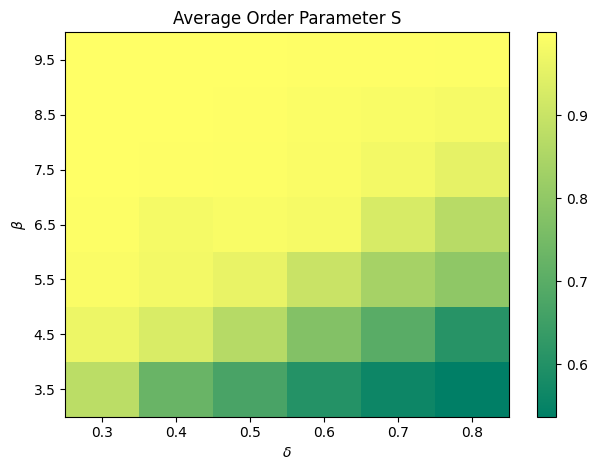

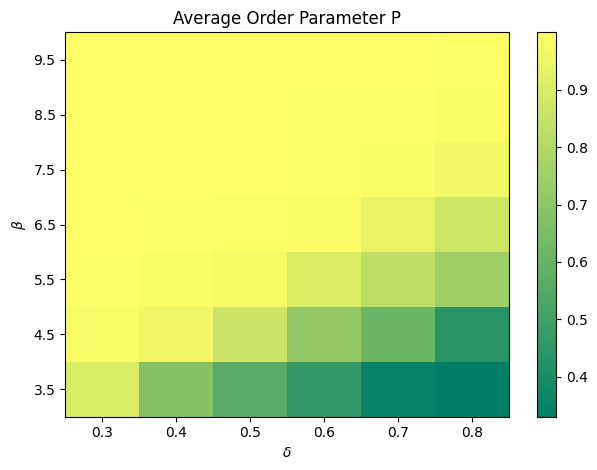

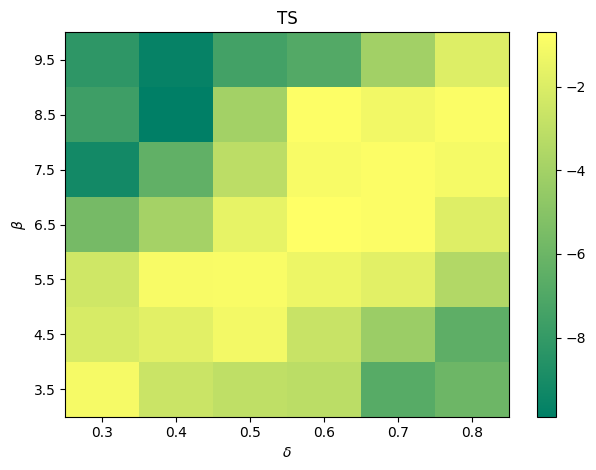

In [13]:
# explore the results in a heatmap
op_s_avg = op_s_results.mean(axis=0)
plot_heatmap(op_s_avg, delta_list, beta_list, cmap='summer', title='Average Order Parameter S')
op_p_avg = op_p_results.mean(axis=0)
plot_heatmap(op_p_avg, delta_list, beta_list, cmap='summer', title='Average Order Parameter P')
global_reward4_avg = global_reward4_results.mean(axis=0)
plot_heatmap(global_reward4_avg, delta_list, beta_list, cmap='summer', title='TS')

In [14]:
T = 2200

pos = np.zeros((T - t_transient, n + n_special, 2))
pher = np.zeros((T - t_transient, Lx, Ly))
rew4 = np.zeros((T - t_transient, 1))
withdrawal_time = tmax - t_transient

beta = 5.5
delta = 0.7
print(f"Testing with delta = {delta}, beta = {beta}")

env = Ants_move_special(
    n,
    Lx,
    Ly,
    delta,
    beta,
    decay_rate,
    eta,
    eta_special,
    beta,
    delta,
    tmax,
    n_special,
    t_transient,
)

env.reset_objects()
env.transient()

for t in range(T - t_transient):
    env.update()
    pos[t, :, :] = env.positions.copy()
    pher[t, :, :] = env.pheromones.copy()

    # 1. Calcolo dei parametri d'ordine al tempo t
    rho_t = compute_density(env.positions, Lx, Ly, n)
    s_t = order_parameter_s(env.pheromones, Lx * Ly)
    p_t = order_parameter_p(env.pheromones, rho_t)

    # 2. Estrazione metriche del grafo delle componenti connesse
    metrics_for_components = global_reward(env)
    n_edges = metrics_for_components[:, 0]
    n_nodes = metrics_for_components[:, 1]
    num_components = len(metrics_for_components)

    # 3. Penalità sugli archi
    edge_pen = np.divide(
        -n_edges,
        n_nodes - 1,
        out=np.zeros_like(n_edges, dtype=float),
        where=(n_nodes > 1),
    )

    # 4. Calcolo e salvataggio di reward4 al passo t
    reward4 = np.sum(edge_pen) + 0.5 * num_components * (
        s_t * min(env.Lx, np.mean(n_nodes)) / env.Lx + p_t
    )
    rew4[t] = reward4

    if t == withdrawal_time:
        env.pheromones *= 0

order_param_s = []
order_param_p = []

rhos = [compute_density(pos[i], Lx, Ly, n) for i in range(len(pos))]

for pheromones, rho in zip(pher, rhos):
    s = order_parameter_s(pheromones, Lx * Ly)
    p = order_parameter_p(pheromones, rho)
    order_param_s.append(s)
    order_param_p.append(p)

# Media della metrica reward4 negli ultimi 50 passi temporali
reward4_final_mean = rew4[-50:].mean()

Testing with delta = 0.7, beta = 5.5


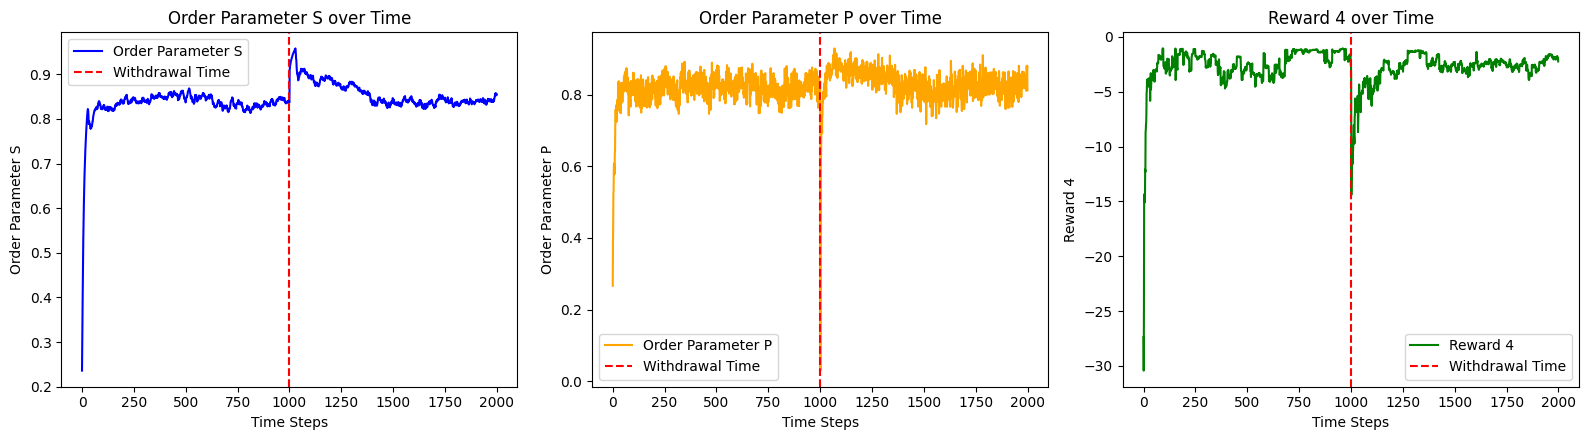

In [36]:
plt.figure(figsize=(16, 4.5))

# Subplot 1: Order Parameter S
plt.subplot(1, 3, 1)
plt.plot(order_param_s, label='Order Parameter S', color='blue')
plt.axvline(x=withdrawal_time, color='red', linestyle='--', label='Withdrawal Time')
plt.title('Order Parameter S over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter S')
plt.legend()

# Subplot 2: Order Parameter P
plt.subplot(1, 3, 2)
plt.plot(order_param_p, label='Order Parameter P', color='orange')
plt.axvline(x=withdrawal_time, color='red', linestyle='--', label='Withdrawal Time')
plt.title('Order Parameter P over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter P')
plt.legend()

# Subplot 3: Reward 4
plt.subplot(1, 3, 3)
plt.plot(rew4, label='Reward 4', color='green')
plt.axvline(x=withdrawal_time, color='red', linestyle='--', label='Withdrawal Time')
plt.title('Reward 4 over Time')
plt.xlabel('Time Steps')
plt.ylabel('Reward 4')
plt.legend()

plt.tight_layout()
plt.show()

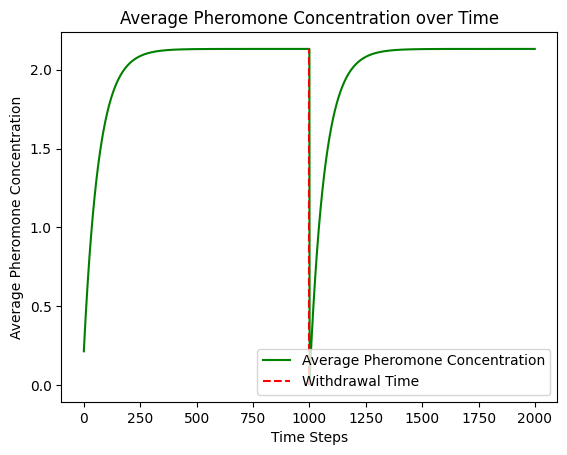

In [15]:
plt.plot(np.mean(pher, axis=(1,2)), label='Average Pheromone Concentration', color='green')
plt.title('Average Pheromone Concentration over Time')
plt.xlabel('Time Steps')
plt.ylabel('Average Pheromone Concentration')
plt.vlines(x=withdrawal_time,
            color='red', linestyle='--', label='Withdrawal Time', ymin=0, ymax=np.mean(pher, axis=(1,2)).max())
plt.legend()
plt.show()

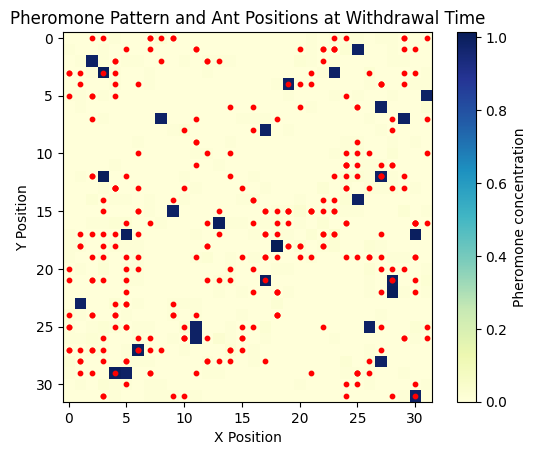

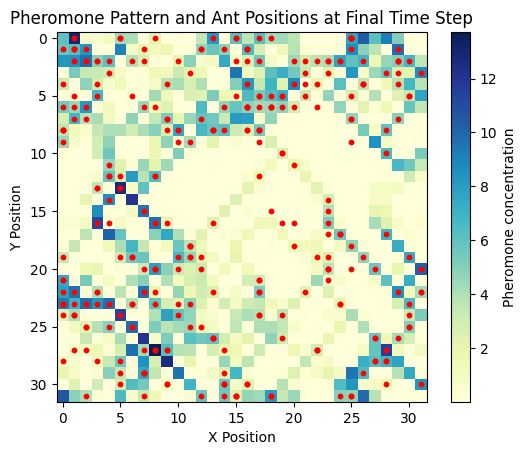

In [16]:
plt.imshow(np.array(pher)[withdrawal_time+1], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[withdrawal_time][:n, 1], np.array(pos)[withdrawal_time][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Withdrawal Time')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()

plt.imshow(np.array(pher)[-1], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[-1][:n, 1], np.array(pos)[-1][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Final Time Step')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()


In [40]:
# save the results
np.savez(f"results_dismalting.npz",
         op_s_results=op_s_results,
         op_p_results=op_p_results,
         global_reward4_results=global_reward4_results
)